In [1]:
import os
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.customer_features import build_customer_profiles
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs(ROOT / "reports/figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

df = pd.read_parquet(ROOT / "data/processed/retail_processed.parquet")
print(f"Tổng số dòng giao dịch: {len(df):,} | Số khách hàng duy nhất: {df['customer_id'].nunique():,}")

Tổng số dòng giao dịch: 794,437 | Số khách hàng duy nhất: 5,876


In [2]:
# Tách giao dịch mua thành công và giao dịch hủy
df_valid = df[~df["is_cancelled"]].copy()
df_cancel = df[df["is_cancelled"]].copy()

# Bảng thống kê mô tả các biến số học trên đơn hàng hợp lệ
num_summary = pd.DataFrame({
    "Mean": df_valid[["quantity", "price", "total_amount"]].mean(),
    "SD": df_valid[["quantity", "price", "total_amount"]].std(),
    "Median": df_valid[["quantity", "price", "total_amount"]].median(),
    "IQR": df_valid[["quantity", "price", "total_amount"]].quantile(0.75) - df_valid[["quantity", "price", "total_amount"]].quantile(0.25),
    "Max": df_valid[["quantity", "price", "total_amount"]].max()
}).round(2)
display(num_summary)

# Dùng cùng định nghĩa với notebook 03: tỷ lệ cuối tuần/cao điểm theo hóa đơn.
customer_df = build_customer_profiles(df)
print(f"Hồ sơ hành vi khách hàng: {customer_df.shape[0]:,} khách hàng, {customer_df.shape[1]} đặc trưng")
display(customer_df.describe().round(2))

,Mean,SD,Median,IQR,Max
quantity,13.51,146.07,6.00,10.00,80995.0
price,2.95,4.38,1.95,2.50,649.5
total_amount,21.99,225.89,12.48,14.85,168469.6


Hồ sơ hành vi khách hàng: 5,853 khách hàng, 21 đặc trưng


,first_purchase,last_purchase,frequency,monetary,avg_order_value,weekend_ratio,peak_month_ratio,recency_days,tenure_days,observation_days,total_items,unique_products,total_invoices,cancelled_invoices,cancel_rate,is_repeat_buyer
count,5853,5853,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00,5853.00
mean,2010-08-23 00:07:50.179395072,2011-05-23 18:19:45.576627456,6.25,2918.35,384.55,0.14,0.48,199.78,274.39,474.54,1793.78,82.19,7.49,1.24,0.11,0.72
min,2009-12-01 07:45:00,2009-12-01 10:49:00,1.00,2.95,2.95,0.00,0.00,0.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00
25%,2010-02-11 09:45:00,2010-11-25 15:59:00,1.00,340.85,176.12,0.00,0.20,25.00,1.00,312.00,189.00,19.00,2.00,0.00,0.00,0.00
50%,2010-06-28 14:05:00,2011-09-05 15:19:00,3.00,856.03,277.94,0.00,0.50,95.00,223.00,530.00,484.00,45.00,4.00,0.00,0.00,1.00
75%,2011-02-01 11:42:00,2011-11-14 12:55:00,7.00,2240.90,410.66,0.17,0.80,379.00,512.00,667.00,1352.00,103.00,8.00,1.00,0.20,1.00
max,2011-12-09 12:16:00,2011-12-09 12:50:00,375.00,580987.04,84236.25,1.00,1.00,738.00,739.00,739.00,367072.00,2547.00,468.00,93.00,0.80,1.00
std,NaN,NaN,12.76,14335.23,1254.58,0.26,0.36,208.54,258.49,223.18,8890.63,116.50,15.41,3.33,0.16,0.45


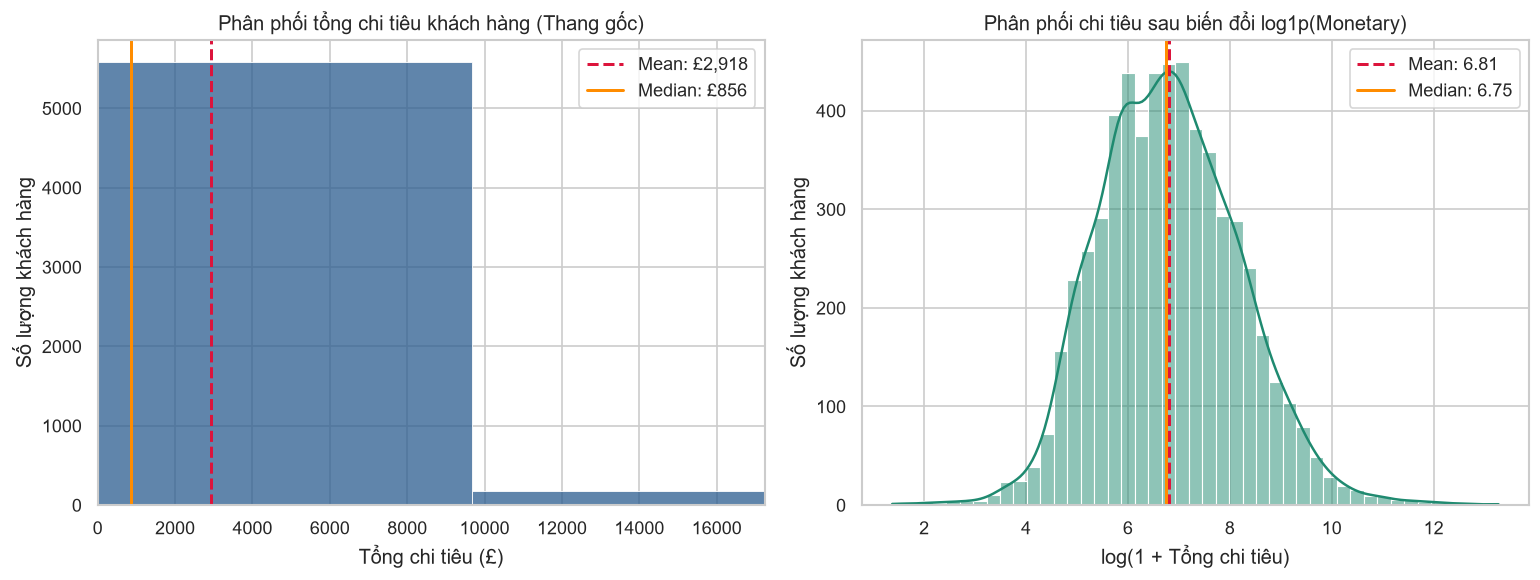

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ trái: Phân phối gốc (lệch phải mạnh)
sns.histplot(customer_df["monetary"], bins=60, ax=axes[0], color="#2b5c8f")
axes[0].axvline(customer_df["monetary"].mean(), color="crimson", linestyle="--", linewidth=1.8, label=f"Mean: £{customer_df['monetary'].mean():,.0f}")
axes[0].axvline(customer_df["monetary"].median(), color="darkorange", linestyle="-", linewidth=1.8, label=f"Median: £{customer_df['monetary'].median():,.0f}")
axes[0].set_title("Phân phối tổng chi tiêu khách hàng (Thang gốc)")
axes[0].set_xlabel("Tổng chi tiêu (£)")
axes[0].set_ylabel("Số lượng khách hàng")
axes[0].set_xlim(0, customer_df["monetary"].quantile(0.98))
axes[0].legend()

# Biểu đồ phải: Phân phối sau biến đổi log1p (gần chuẩn)
log_monetary = np.log1p(customer_df["monetary"])
sns.histplot(log_monetary, bins=45, kde=True, ax=axes[1], color="#1f8a70")
axes[1].axvline(log_monetary.mean(), color="crimson", linestyle="--", linewidth=1.8, label=f"Mean: {log_monetary.mean():.2f}")
axes[1].axvline(log_monetary.median(), color="darkorange", linestyle="-", linewidth=1.8, label=f"Median: {log_monetary.median():.2f}")
axes[1].set_title("Phân phối chi tiêu sau biến đổi log1p(Monetary)")
axes[1].set_xlabel("log(1 + Tổng chi tiêu)")
axes[1].set_ylabel("Số lượng khách hàng")
axes[1].legend()

plt.tight_layout()
fig.savefig(ROOT / "reports/figures/01_monetary_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

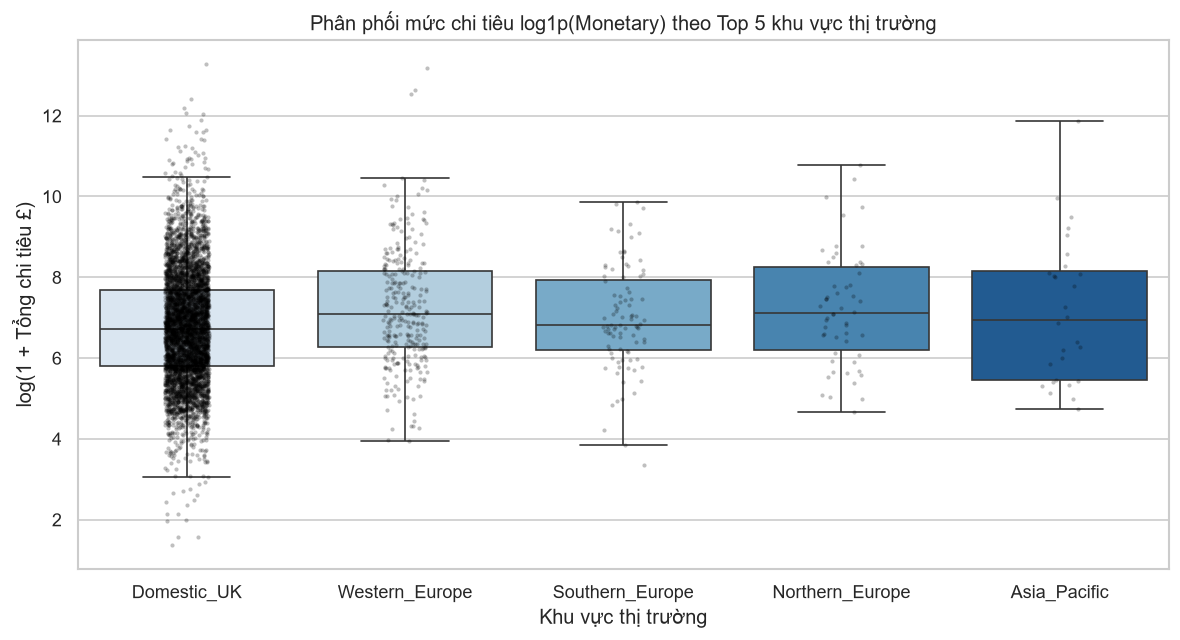

In [4]:
top_regions = customer_df["region"].value_counts().head(5).index.tolist()
df_reg = customer_df[customer_df["region"].isin(top_regions)].copy()
df_reg["log_monetary"] = np.log1p(df_reg["monetary"])

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(
    data=df_reg, x="region", y="log_monetary",
    order=top_regions, hue="region", hue_order=top_regions, legend=False, showfliers=False, palette="Blues", ax=ax
)
sns.stripplot(
    data=df_reg, x="region", y="log_monetary",
    order=top_regions, color="black", alpha=0.25, size=2.5, jitter=True, ax=ax
)
ax.set_title("Phân phối mức chi tiêu log1p(Monetary) theo Top 5 khu vực thị trường")
ax.set_xlabel("Khu vực thị trường")
ax.set_ylabel("log(1 + Tổng chi tiêu £)")
plt.tight_layout()
fig.savefig(ROOT / "reports/figures/02_spending_by_region.png", dpi=300, bbox_inches="tight")
plt.show()

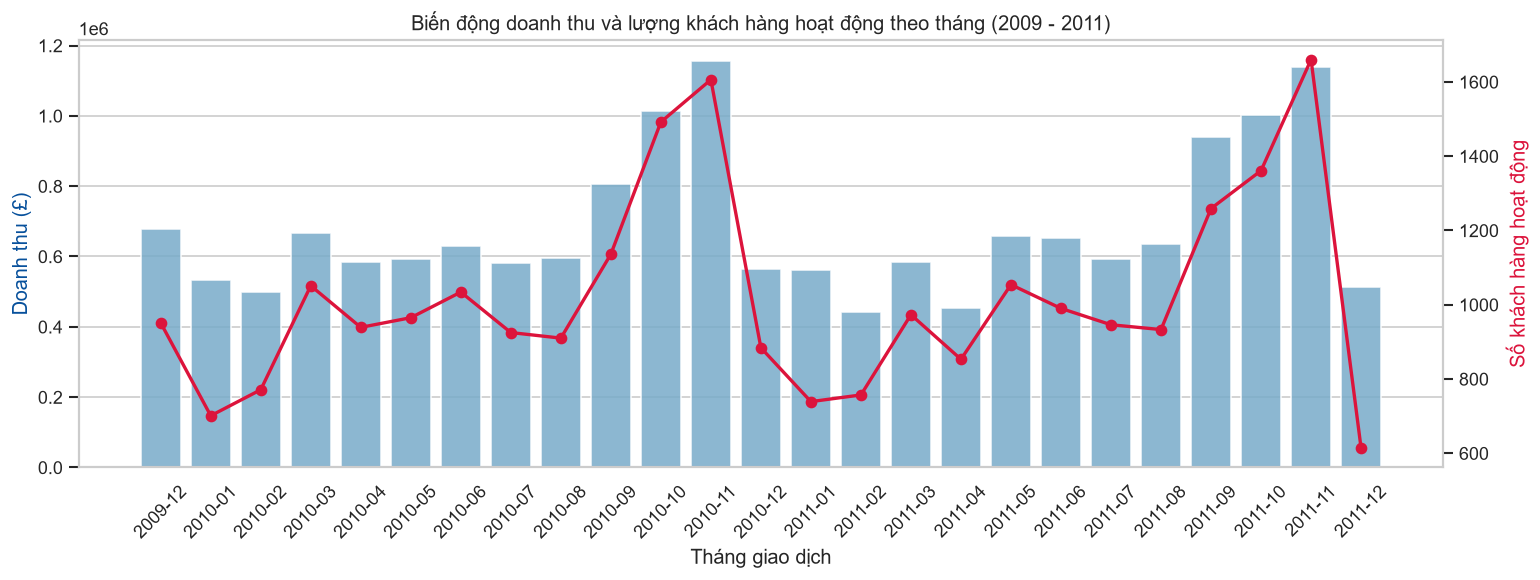

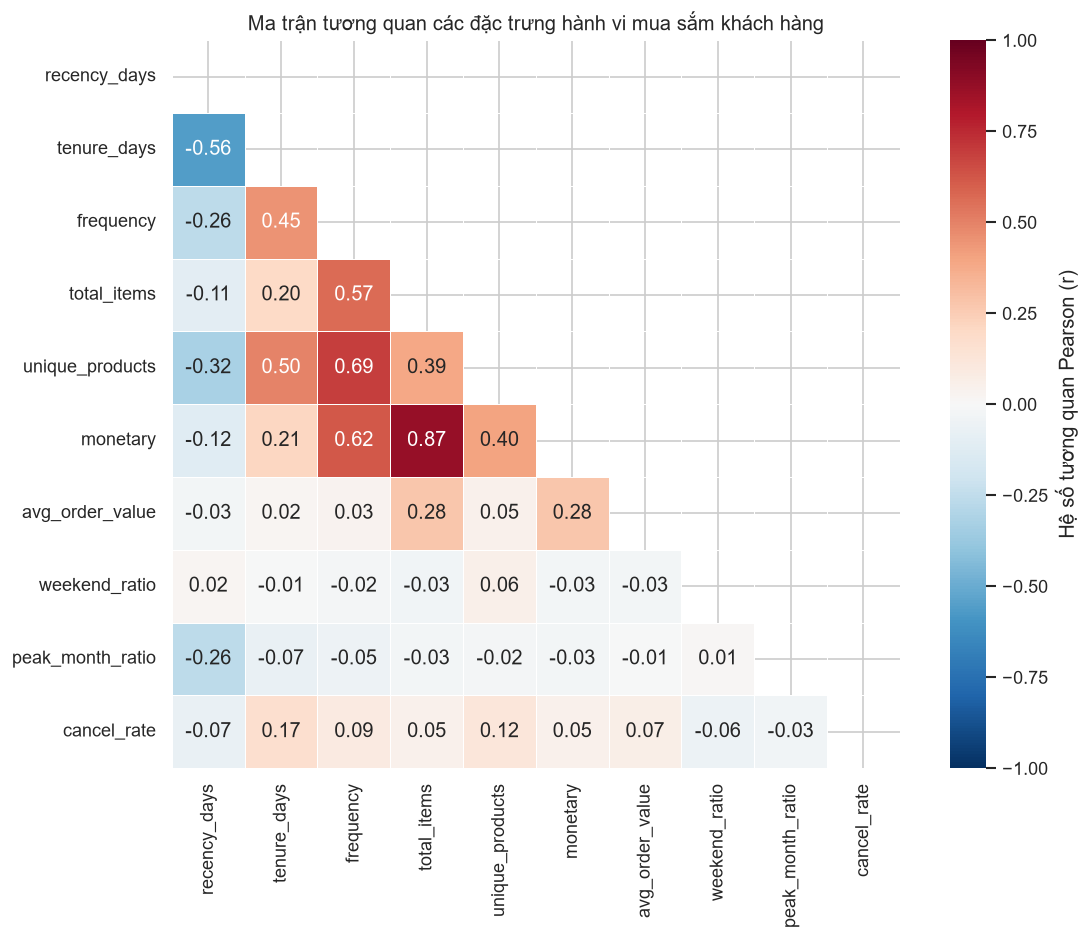

In [5]:
# Biểu đồ 3: Xu hướng doanh thu & số lượng khách hoạt động theo tháng
df_valid["year_month"] = df_valid["invoice_date"].dt.to_period("M").astype(str)
monthly = df_valid.groupby("year_month").agg(
    revenue=("total_amount", "sum"),
    active_customers=("customer_id", "nunique")
).reset_index()

fig, ax1 = plt.subplots(figsize=(13, 5))
sns.barplot(data=monthly, x="year_month", y="revenue", color="#6baed6", alpha=0.85, ax=ax1)
ax1.set_ylabel("Doanh thu (£)", color="#08519c")
ax1.set_xlabel("Tháng giao dịch")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(monthly["year_month"], monthly["active_customers"], color="crimson", marker="o", linewidth=2, label="Khách hàng hoạt động")
ax2.set_ylabel("Số khách hàng hoạt động", color="crimson")
ax2.grid(False)
plt.title("Biến động doanh thu và lượng khách hàng hoạt động theo tháng (2009 - 2011)")
plt.tight_layout()
fig.savefig(ROOT / "reports/figures/03_monthly_revenue_trend.png", dpi=300, bbox_inches="tight")
plt.show()

# Biểu đồ 4: Ma trận tương quan các biến hành vi khách hàng (Che nửa trên, neo màu tại 0)
corr_cols = ["recency_days", "tenure_days", "frequency", "total_items", "unique_products", "monetary", "avg_order_value", "weekend_ratio", "peak_month_ratio", "cancel_rate"]
corr = customer_df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, cbar_kws={"label": "Hệ số tương quan Pearson (r)"}, ax=ax
)
ax.set_title("Ma trận tương quan các đặc trưng hành vi mua sắm khách hàng")
plt.tight_layout()
fig.savefig(ROOT / "reports/figures/04_behavior_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()